### Part A - Image Representation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from PIL import Image
from io import BytesIO
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)  

folder = Path.cwd()
zip_files = list(folder.glob("*.zip"))

print("Current folder:", folder)
print("Zip files found:", [file.name for file in zip_files])

if len(zip_files) != 1:
    raise ValueError("Please keep exactly one dataset ZIP file in this folder.")

zip_path = zip_files[0]

with zipfile.ZipFile(zip_path, "r") as z:
    image_files = sorted([
        name for name in z.namelist()
        if name.lower().endswith((".pgm", ".png", ".jpg", ".jpeg"))
        and not Path(name).name.startswith("._")
        and "__MACOSX" not in name
    ])

print("Total images found:", len(image_files))
print("Sample image paths:", image_files[:10])

Current folder: c:\Users\choks\OneDrive\Desktop\DAU\Sem-1\Machine Learning Lab\202618035_HetChokshi_DS605\202618035_lab_7
Zip files found: ['archive (3).zip']
Total images found: 400
Sample image paths: ['s1/1.pgm', 's1/10.pgm', 's1/2.pgm', 's1/3.pgm', 's1/4.pgm', 's1/5.pgm', 's1/6.pgm', 's1/7.pgm', 's1/8.pgm', 's1/9.pgm']


#### Loading images and creating labels

In [2]:
images = []
labels = []

with zipfile.ZipFile(zip_path, "r") as z:
    for file in image_files:
        parts = Path(file).parts
        subject = next(
            (p for p in parts if p.startswith("s") and p[1:].isdigit()),
            None
        )

        if subject is None:
            continue

        with z.open(file) as f:
            img = Image.open(BytesIO(f.read())).convert("L")
            img_array = np.array(img, dtype=np.float64)

        images.append(img_array)
        labels.append(int(subject[1:]))

images = np.array(images)
labels = np.array(labels)

print("Image shape:", images.shape)
print("Labels shape:",labels.shape)
print("Unique subjects:", len(np.unique(labels)))
print("Pixel intensity range:", images.min(), "to", images.max())

Image shape: (400, 112, 92)
Labels shape: (400,)
Unique subjects: 40
Pixel intensity range: 0.0 to 251.0


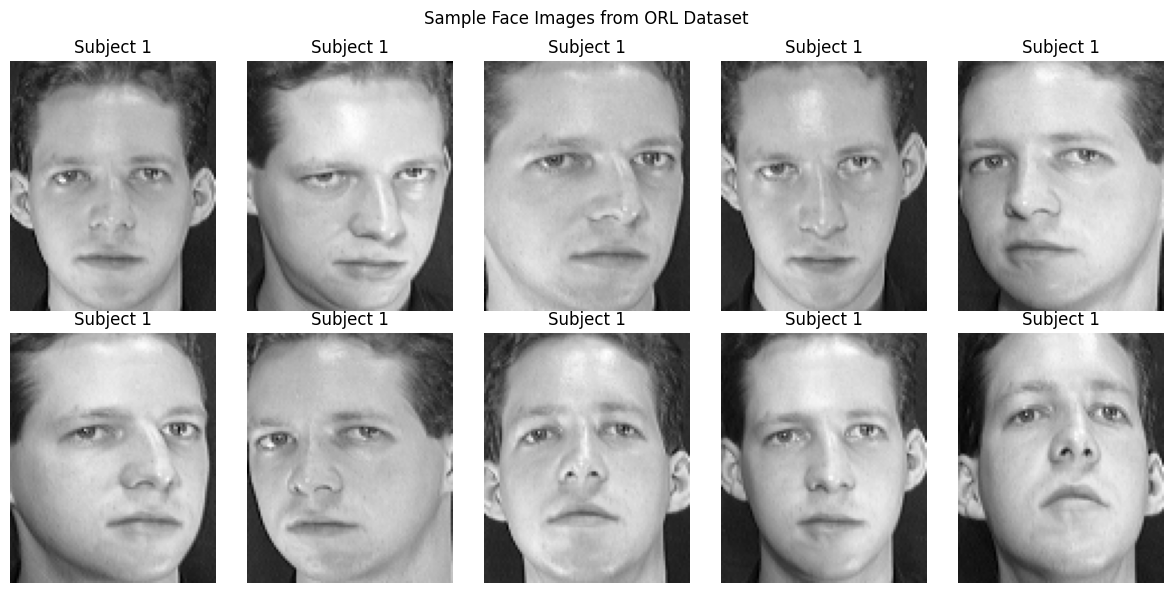

In [3]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {labels[i]}")
    ax.axis("off")

plt.suptitle("Sample Face Images from ORL Dataset")
plt.tight_layout()
plt.show()


#### Flattening the images

In [4]:

n_samples, height, width = images.shape

X = images.reshape(n_samples, height * width)
y = labels

print("Original image shape:", images.shape)
print("Flattened feature matrix:", X.shape)
print("Labels shape:", y.shape)


Original image shape: (400, 112, 92)
Flattened feature matrix: (400, 10304)
Labels shape: (400,)


#### Train Test Split

In [5]:
X_train,X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training subjects:", len(np.unique(y_train)))
print("Testing subjects:", len(np.unique(y_test)))

assert set(np.unique(y_train)) == set(np.unique(y_test))


Training data: (320, 10304)
Testing data: (80, 10304)
Training subjects: 40
Testing subjects: 40


### Part B - PCA, Eigenfaces and Compression

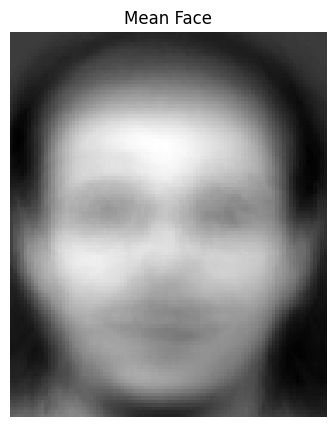

Mean face shape: (10304,)
Centered training data: (320, 10304)


In [6]:
mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

plt.figure(figsize=(5, 5))
plt.imshow(mean_face.reshape(height, width), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

print("Mean face shape:", mean_face.shape)
print("Centered training data:", X_train_centered.shape)

In [7]:

n_train = X_train_centered.shape[0]

small_cov = (
    X_train_centered @ X_train_centered.T
) / (n_train - 1)

eigenvalues, small_eigenvectors = np.linalg.eigh(small_cov)

indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
small_eigenvectors = small_eigenvectors[:, indices]

valid = eigenvalues > 1e-8

eigenvalues = eigenvalues[valid]
small_eigenvectors = small_eigenvectors[:, valid]

principal_components = (
    X_train_centered.T @ small_eigenvectors
)

principal_components /= np.sqrt(
    (n_train - 1) * eigenvalues
)

principal_components = principal_components.T

print("Principal components shape:", principal_components.shape)
print("Eigenvalues shape:", eigenvalues.shape)


Principal components shape: (319, 10304)
Eigenvalues shape: (319,)


#### Implementing PCA using SVD

In [8]:

U, S, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

svd_eigenvalues = (S ** 2) / (n_train - 1)

svd_components = Vt

print("SVD components shape:", svd_components.shape)

print(
    "Eigenvalues match:",
    np.allclose(
        eigenvalues,
        svd_eigenvalues[:len(eigenvalues)],
        rtol=1e-5,
        atol=1e-5
    )
)


SVD components shape: (320, 10304)
Eigenvalues match: True


Components required for 90% variance: 98


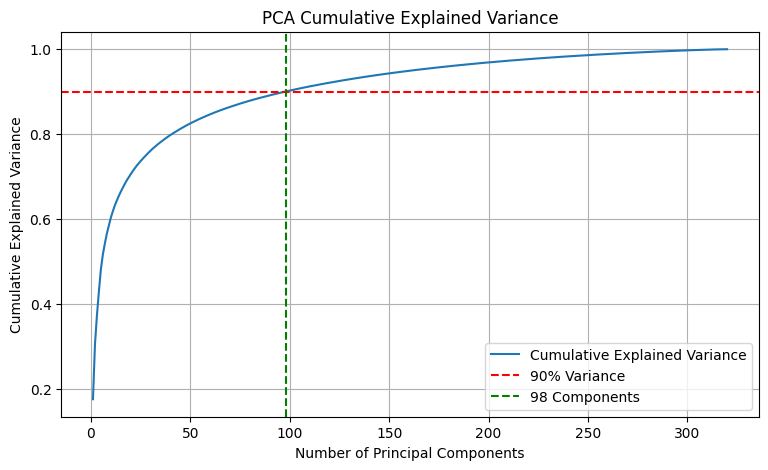

In [9]:

explained_variance_ratio = (
    svd_eigenvalues / np.sum(svd_eigenvalues)
)

cumulative_variance = np.cumsum(explained_variance_ratio)

k_90 = np.searchsorted(cumulative_variance, 0.90) + 1

print("Components required for 90% variance:", k_90)

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    label="Cumulative Explained Variance"
)

plt.axhline(0.90, color="red", linestyle="--", label="90% Variance")
plt.axvline(k_90, color="green", linestyle="--", label=f"{k_90} Components")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()


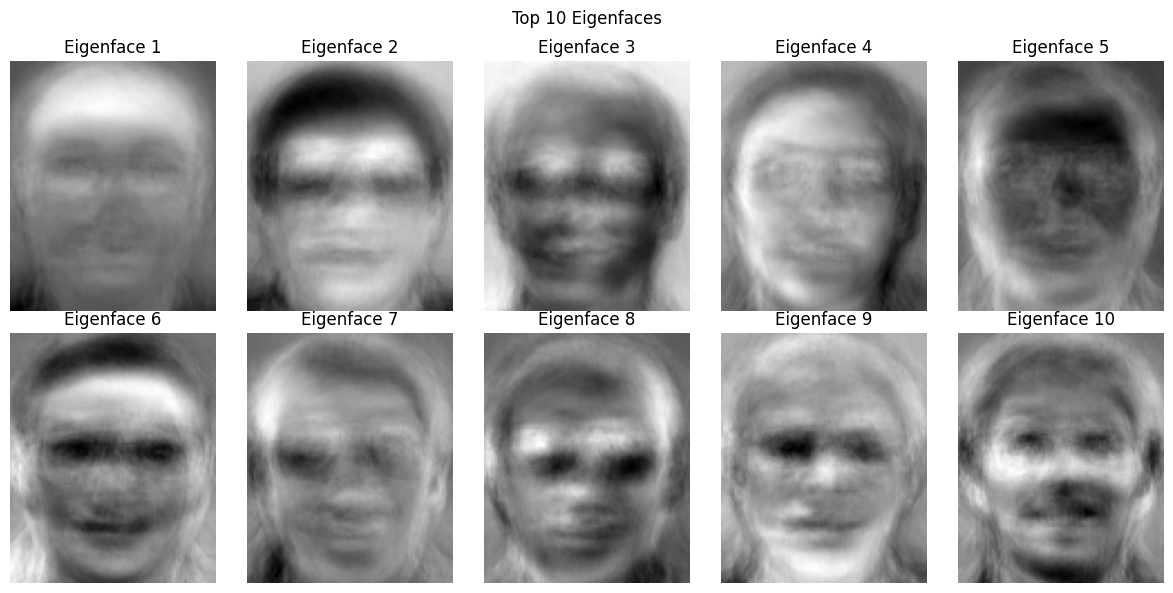

In [10]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    eigenface = svd_components[i].reshape(height, width)

    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("Top 10 Eigenfaces")
plt.tight_layout()
plt.show()


In [11]:

components_90 = svd_components[:k_90]

X_train_pca = X_train_centered @ components_90.T
X_test_pca = X_test_centered @ components_90.T

print("Original training shape:", X_train.shape)
print("Reduced training shape:", X_train_pca.shape)

print("Original testing shape:", X_test.shape)
print("Reduced testing shape:", X_test_pca.shape)


Original training shape: (320, 10304)
Reduced training shape: (320, 98)
Original testing shape: (80, 10304)
Reduced testing shape: (80, 98)


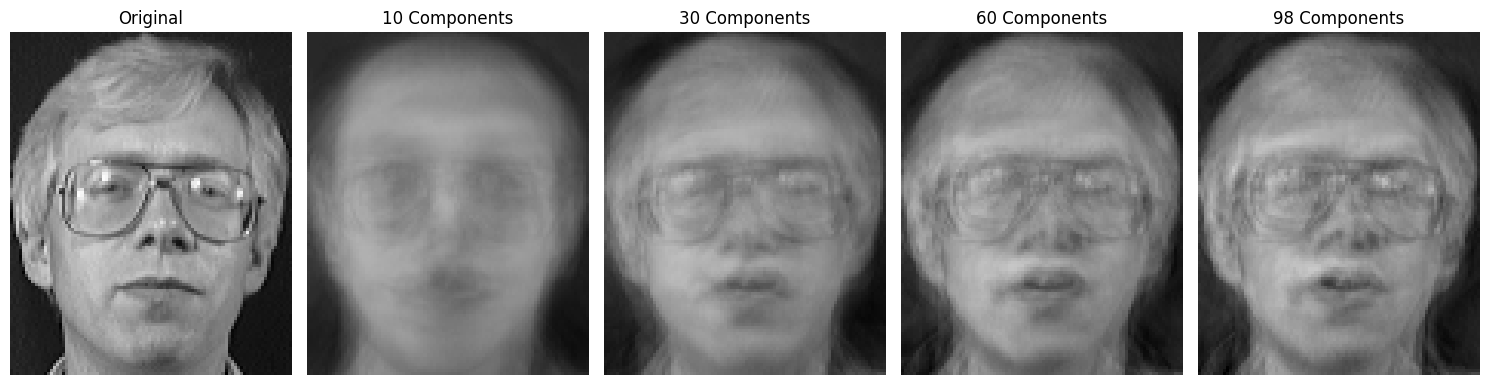

In [12]:

component_counts = sorted(set(
    [10, 30, 60, k_90]
))

sample = X_test[0]
sample_centered = sample - mean_face

fig, axes = plt.subplots(
    1,
    len(component_counts) + 1,
    figsize=(15, 4)
)

axes[0].imshow(sample.reshape(height, width), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

for i, k in enumerate(component_counts):
    components = svd_components[:k]

    projected = sample_centered @ components.T
    reconstructed = projected @ components + mean_face

    axes[i + 1].imshow(
        reconstructed.reshape(height, width),
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i + 1].set_title(f"{k} Components")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()


In [13]:

results = []

for k in component_counts:
    components = svd_components[:k]

    projected = X_test_centered @ components.T
    reconstructed = projected @ components + mean_face

    mse = np.mean((X_test - reconstructed) ** 2)

    results.append({
        "Components": k,
        "Explained Variance (%)": round(
            cumulative_variance[k - 1] * 100, 2
        ),
        "Reconstruction MSE": round(mse, 2)
    })

reconstruction_df = pd.DataFrame(results)

display(reconstruction_df)


,Components,Explained Variance (%),Reconstruction MSE
0,10,60.40,664.88
1,30,76.16,474.28
2,60,84.70,380.93
3,98,90.06,334.99


In [14]:

original_values = X_train.size

compressed_values = (
    X_train_pca.size
    + components_90.size
    + mean_face.size
)

storage_reduction = (
    1 - compressed_values / original_values
) * 100

print("Original stored values:", original_values)
print("PCA stored values:", compressed_values)
print(f"Storage reduction: {storage_reduction:.2f}%")


Original stored values: 3297280
PCA stored values: 1051456
Storage reduction: 68.11%


### Part C - Recognition in PCA Space

#### Implementing Euclidean distance matching

In [15]:

def nearest_neighbor_predict(X_train_features, X_test_features, y_train):
    distances = np.sum(
        (X_test_features[:, None, :] - X_train_features[None, :, :]) ** 2,
        axis=2
    )

    nearest_indices = np.argmin(distances, axis=1)

    predictions = y_train[nearest_indices]

    return predictions, nearest_indices, distances


y_pred_pca, nearest_indices_pca, distances_pca = nearest_neighbor_predict(
    X_train_pca,
    X_test_pca,
    y_train
)

print("PCA predictions shape:", y_pred_pca.shape)
print("First 10 predicted labels:", y_pred_pca[:10])
print("First 10 actual labels:", y_test[:10])


PCA predictions shape: (80,)
First 10 predicted labels: [ 2 36 19 17 40 24 33 20  4 35]
First 10 actual labels: [ 2 36 19 17 40 24 33 20  4 35]


#### Calculating PCA recognition accuracy

In [16]:

pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"PCA Recognition Accuracy: {pca_accuracy * 100:.2f}%")
print("Correct predictions:", np.sum(y_test == y_pred_pca))
print("Incorrect predictions:", np.sum(y_test != y_pred_pca))


PCA Recognition Accuracy: 96.25%
Correct predictions: 77
Incorrect predictions: 3


#### Performing face recognition using raw pixels

In [17]:

y_pred_raw, nearest_indices_raw, distances_raw = nearest_neighbor_predict(
    X_train,
    X_test,
    y_train
)

raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Pixel Recognition Accuracy: {raw_accuracy * 100:.2f}%")
print(f"PCA Recognition Accuracy: {pca_accuracy * 100:.2f}%")


Raw Pixel Recognition Accuracy: 96.25%
PCA Recognition Accuracy: 96.25%


#### Comparing recognition accuracy

,Method,Features,Accuracy (%)
0,Raw Pixels,10304,96.25
1,PCA Features,98,96.25


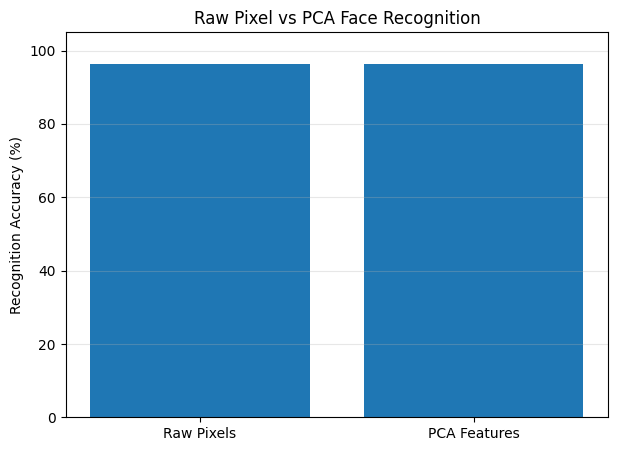

In [18]:

comparison_df = pd.DataFrame({
    "Method": ["Raw Pixels", "PCA Features"],
    "Features": [X_train.shape[1], X_train_pca.shape[1]],
    "Accuracy (%)": [raw_accuracy * 100, pca_accuracy * 100]
})

display(comparison_df)

plt.figure(figsize=(7, 5))
plt.bar(
    comparison_df["Method"],
    comparison_df["Accuracy (%)"]
)

plt.ylabel("Recognition Accuracy (%)")
plt.title("Raw Pixel vs PCA Face Recognition")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.show()


#### Visualizing correct and incorrect face matches

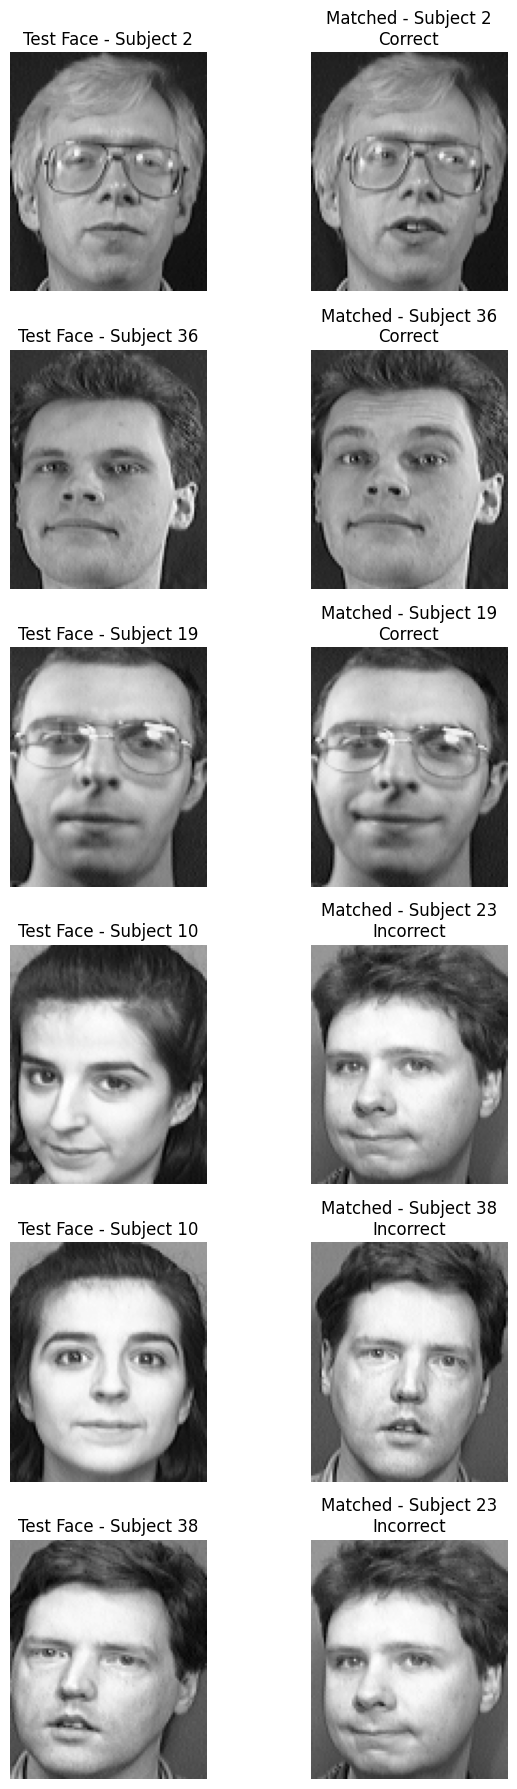

In [19]:

correct_indices = np.where(y_pred_pca == y_test)[0]
incorrect_indices = np.where(y_pred_pca != y_test)[0]

selected_correct = correct_indices[:3]
selected_incorrect = incorrect_indices[:3]

selected_indices = np.concatenate([
    selected_correct,
    selected_incorrect
])

fig, axes = plt.subplots(
    len(selected_indices),
    2,
    figsize=(7, 3 * len(selected_indices)),
    squeeze=False
)

for row, idx in enumerate(selected_indices):
    test_face = X_test[idx].reshape(height, width)

    matched_face = X_train[
        nearest_indices_pca[idx]
    ].reshape(height, width)

    is_correct = y_pred_pca[idx] == y_test[idx]

    axes[row, 0].imshow(test_face, cmap="gray")
    axes[row, 0].set_title(f"Test Face - Subject {y_test[idx]}")

    axes[row, 1].imshow(matched_face, cmap="gray")
    axes[row, 1].set_title(
        f"Matched - Subject {y_pred_pca[idx]}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


#### Comparing recognition using different PCA dimentions

,Components,Accuracy (%)
0,10,95.00
1,20,96.25
2,30,96.25
3,50,98.75
4,60,97.50
5,80,97.50
6,98,96.25
7,120,96.25
8,150,96.25


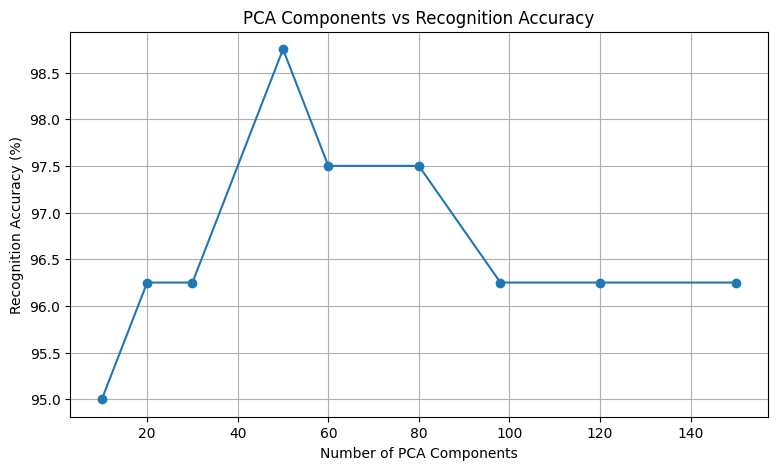

In [20]:

component_options = [10, 20, 30, 50, 60, 80, 98, 120, 150]

accuracy_results = []

for k in component_options:
    components = svd_components[:k]

    train_features = X_train_centered @ components.T
    test_features = X_test_centered @ components.T

    predictions, _, _ = nearest_neighbor_predict(
        train_features,
        test_features,
        y_train
    )

    accuracy_results.append({
        "Components": k,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100
    })

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df)

plt.figure(figsize=(9, 5))
plt.plot(
    accuracy_df["Components"],
    accuracy_df["Accuracy (%)"],
    marker="o"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Recognition Accuracy (%)")
plt.title("PCA Components vs Recognition Accuracy")
plt.grid(True)
plt.show()


### Part D - Traditional Machine Learning

In [21]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import time


In [22]:

models = {
    "KNN": KNeighborsClassifier(n_neighbors=1),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000))
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf"))
    ])
}

model_results = []
trained_models = {}

for name, model in models.items():
    start = time.time()

    model.fit(X_train_pca, y_train)

    training_time = time.time() - start

    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    trained_models[name] = model

    model_results.append({
        "Model": name,
        "Accuracy (%)": accuracy * 100,
        "Training Time (s)": training_time
    })

model_results_df = pd.DataFrame(model_results)

display(model_results_df)


,Model,Accuracy (%),Training Time (s)
0,KNN,96.25,0.011961
1,Logistic Regression,93.75,0.055517
2,SVM,98.75,0.024267


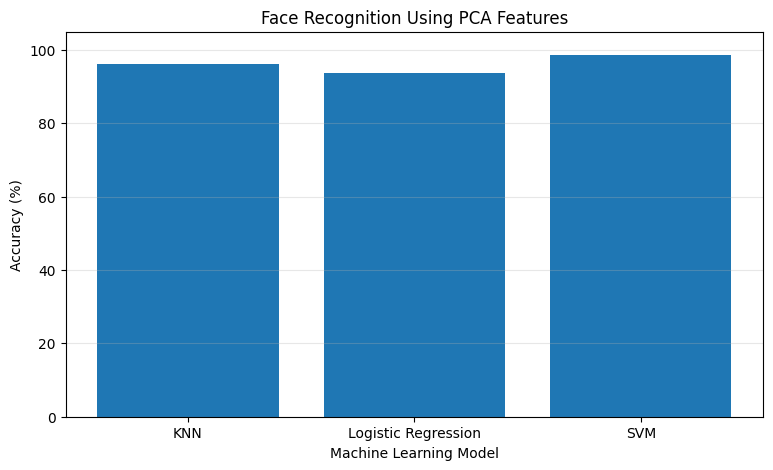

In [23]:

plt.figure(figsize=(9, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy (%)"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Using PCA Features")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.show()


In [24]:

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

param_grids = {
    "KNN": {
        "n_neighbors": [1, 3, 5, 7],
        "weights": ["uniform", "distance"]
    },
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.001, 0.01]
    }
}

best_models = {}
tuning_results = []

for name, model in models.items():
    search = GridSearchCV(
        model,
        param_grids[name],
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X_train_pca, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV Accuracy (%)": search.best_score_ * 100
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)


,Model,Best Parameters,CV Accuracy (%)
0,KNN,"{'n_neighbors': 1, 'weights': 'uniform'}",95.9375
1,Logistic Regression,{'classifier__C': 1},92.5000
2,SVM,"{'classifier__C': 10, 'classifier__gamma': 0.001}",91.8750


In [25]:

final_results = []

for name, model in best_models.items():
    predictions = model.predict(X_test_pca)

    accuracy = accuracy_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "Test Accuracy (%)": accuracy * 100
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df)


,Model,Test Accuracy (%)
0,KNN,96.25
1,Logistic Regression,93.75
2,SVM,95.00


,Model,Baseline Accuracy (%),Tuned Accuracy (%)
0,KNN,96.25,96.25
1,Logistic Regression,93.75,93.75
2,SVM,98.75,95.00


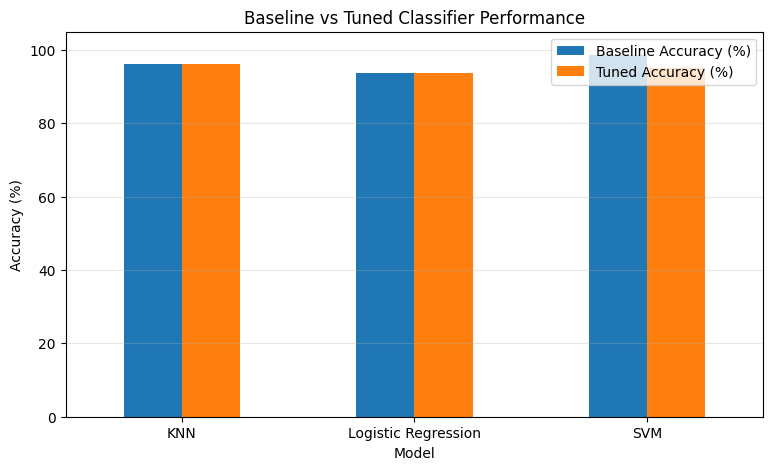

In [26]:

comparison = model_results_df[
    ["Model", "Accuracy (%)"]
].merge(
    final_results_df,
    on="Model"
)

comparison.columns = [
    "Model",
    "Baseline Accuracy (%)",
    "Tuned Accuracy (%)"
]

display(comparison)

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy (%)")
plt.title("Baseline vs Tuned Classifier Performance")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [27]:

for name, model in best_models.items():
    predictions = model.predict(X_test_pca)

    print(f"\n{name} Classification Report")
    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )



KNN Classification Report
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       0.00      0.00      0.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
          17       1.00      1.00      1.00         2


In [28]:

from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

comparison.to_csv(output_dir / "model_comparison.csv", index=False)
accuracy_df.to_csv(output_dir / "pca_accuracy_comparison.csv", index=False)
reconstruction_df.to_csv(output_dir / "reconstruction_results.csv", index=False)

print("Results saved successfully!")


Results saved successfully!


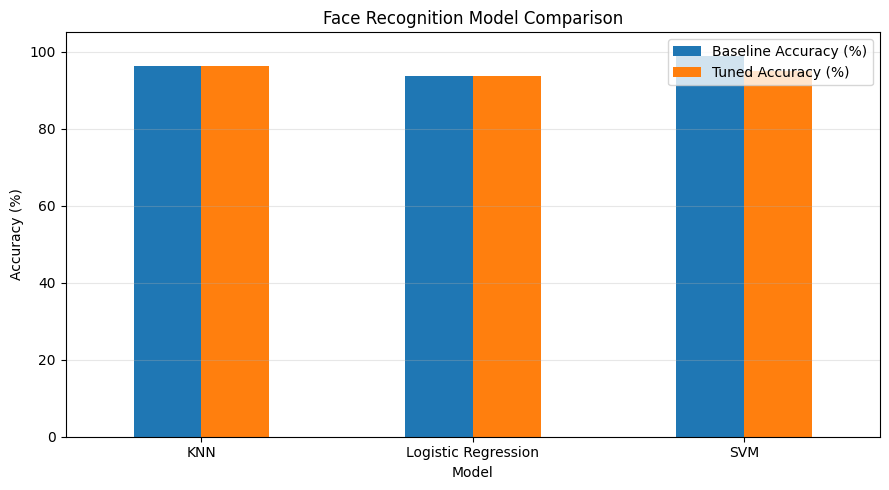

In [29]:

ax = comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Model Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [30]:

print("DS605 LAB ASSIGNMENT 7 - FINAL SUMMARY")
print("-" * 45)

print("Dataset: AT&T ORL Face Dataset")
print("Total Images:", len(images))
print("Total Subjects:", len(np.unique(labels)))

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("Original Features:", X_train.shape[1])
print("PCA Components:", k_90)

print(f"Explained Variance: {cumulative_variance[k_90-1]*100:.2f}%")

print(f"Raw Pixel Recognition: {raw_accuracy*100:.2f}%")
print(f"PCA Recognition: {pca_accuracy*100:.2f}%")

print("\nMachine Learning Results:")
print(comparison.to_string(index=False))

best_baseline = model_results_df.loc[
    model_results_df["Accuracy (%)"].idxmax()
]

print("\nBest Baseline Model:", best_baseline["Model"])
print(f"Best Baseline Accuracy: {best_baseline['Accuracy (%)']:.2f}%")


DS605 LAB ASSIGNMENT 7 - FINAL SUMMARY
---------------------------------------------
Dataset: AT&T ORL Face Dataset
Total Images: 400
Total Subjects: 40
Training Images: 320
Testing Images: 80
Original Features: 10304
PCA Components: 98
Explained Variance: 90.06%
Raw Pixel Recognition: 96.25%
PCA Recognition: 96.25%

Machine Learning Results:
              Model  Baseline Accuracy (%)  Tuned Accuracy (%)
                KNN                  96.25               96.25
Logistic Regression                  93.75               93.75
                SVM                  98.75               95.00

Best Baseline Model: SVM
Best Baseline Accuracy: 98.75%
